# Video → 3D: matched visual comparison

Compare **five trained models** with **original SAM 3D** and **ground truth** on the same two held-out objects:

| Model | Trained parts | Input |
|---|---|---|
| Earlier averaging B | Linear connector + video LoRA | Full video, temporal mean |
| Pooler A | Attentive pooler + connector | Full video + masks |
| Pooler B | A + video LoRA | Full video + masks |
| Pooler C | A + SAM LoRA | Full video + masks |
| Pooler D | A + both LoRAs | Full video + masks |
| Original SAM 3D | Frozen pretrained model | First reference image + mask |

The earlier averaging model is **B**, the best earlier run by mean validation Chamfer. The video beside original SAM 3D is visual context; original SAM 3D receives only the reference frame. All predictions are coarse geometry, without texture refinement. Each trained model ran 25 updates.

**Read the saved outputs directly.** They contain the videos, same-camera mesh images, scores and loss curves. The interactive mesh cell adds rotation and zoom when opened in a notebook supporting Plotly.

In [1]:
from pathlib import Path
import base64
import html
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML, Image, display

CODE = Path.cwd()
if CODE.name == "notebooks":
    CODE = CODE.parent
assert (CODE / "pyproject.toml").is_file(), "Open this notebook from Assignment 3 - Group/code"
ASSETS = CODE / "results" / "notebook-comparison"
if not (ASSETS / "comparison.json").exists():
    import wandb
    api = wandb.Api(overrides={"base_url": "https://api.forge.coreweave.com"})
    api.artifact("hprjdk/atdl-video-to-3d/comparison-mask-pooler-g32f534db2662-2026-10-22-14-07-23:v0").download(root=str(ASSETS))
bundle = json.loads((ASSETS / "comparison.json").read_text())
assert len(bundle["objects"]) == 2
assert all(len(obj["models"]) == 6 for obj in bundle["objects"])


In [2]:
def data_uri(path: Path, mime: str) -> str:
    return f"data:{mime};base64," + base64.b64encode(path.read_bytes()).decode()


def score_table(models: list[dict]) -> HTML:
    rows = []
    for model in models:
        m = model["metrics"]
        rows.append(f"<tr><td><a href='{html.escape(model['run_url'], quote=True)}'>{html.escape(model['label'])}</a></td>"
                    f"<td>{'Reference image' if model['key'] == 'native' else 'Full video'}</td>"
                    f"<td>{m['chamfer']:.4f}</td><td>{m['fscore_002']:.3f}</td>"
                    f"<td>{m['newly_revealed/recall_002']:.3f}</td></tr>")
    return HTML("<style>.scores{border-collapse:collapse;width:100%;font:13px system-ui;color:#333;background:#fff}"
                ".scores td,.scores th{padding:10px;text-align:left;border-bottom:1px solid #ddd}"
                ".scores th{background:#f3f3f1;font-weight:600}.scores a{color:#444}</style>"
                "<table class='scores'><thead><tr><th>Model / W&amp;B run</th><th>Input</th>"
                "<th>Chamfer ↓</th><th>F-score ↑</th><th>Newly revealed recall ↑</th></tr></thead><tbody>"
                + "".join(rows) + "</tbody></table>")


def show_context(obj: dict) -> None:
    identity = obj["example_id"]
    video = data_uri(ASSETS / obj["input.mp4"], "video/mp4")
    native = data_uri(ASSETS / "preview" / identity / "native.png", "image/png")
    truth = data_uri(ASSETS / "preview" / identity / "ground_truth.png", "image/png")
    display(HTML(f"<div style='display:grid;grid-template-columns:1fr 1.6fr 1.6fr;gap:12px;align-items:center;background:white;color:#333;padding:12px'>"
                 f"<div><div style='font:600 13px system-ui;margin-bottom:8px'>Input video</div><video controls muted loop playsinline style='width:100%' src='{video}'></video></div>"
                 f"<div><img alt='Original SAM 3D, two views' style='width:100%' src='{native}'></div>"
                 f"<div><img alt='Ground truth, two views' style='width:100%' src='{truth}'></div></div>"))
    rgb = data_uri(ASSETS / obj["reference.png"], "image/png")
    mask = data_uri(ASSETS / obj["reference_mask.png"], "image/png")
    display(HTML(f"<details><summary>Reference image and object-selection mask</summary>"
                 f"<img alt='Reference RGB' src='{rgb}' style='height:200px;margin:10px'><img alt='Reference mask' src='{mask}' style='height:200px;margin:10px'></details>"))


## Overall scores

Lower Chamfer is better. Higher F-score and newly revealed surface recall are better. These scores use the same evaluation objects, generation seed and scan-coordinate convention. Scan/SAM canonical rotation is not established, so this is a pipeline comparison rather than a definitive reconstruction benchmark.

In [3]:
aggregate = []
for index, model in enumerate(bundle["objects"][0]["models"]):
    metrics = {key: float(np.mean([obj["models"][index]["metrics"][key] for obj in bundle["objects"]]))
               for key in ["chamfer", "fscore_002", "newly_revealed/recall_002"]}
    aggregate.append({**model, "metrics": metrics})
display(score_table(aggregate))


Model / W&B run,Input,Chamfer ↓,F-score ↑,Newly revealed recall ↑
Original SAM 3D (reference frame),Reference image,0.0354,0.321,0.348
Earlier averaging B,Full video,0.0611,0.224,0.176
Pooler A: connector,Full video,0.1031,0.133,0.051
Pooler B: video LoRA,Full video,0.1028,0.139,0.055
Pooler C: SAM LoRA,Full video,0.1029,0.138,0.055
Pooler D: both LoRAs,Full video,0.1028,0.139,0.056


## Fixed losses during training

The new runs use the same training probe and all held-out validation clips with fixed noise seeds at each checkpoint. Random training-batch losses are not a clean learning curve. The earlier averaging run used a different validation protocol and is omitted from these curves.

All four fixed validation losses rise early and finish below initialization. This does **not** establish improved generated geometry; compare the actual meshes below.

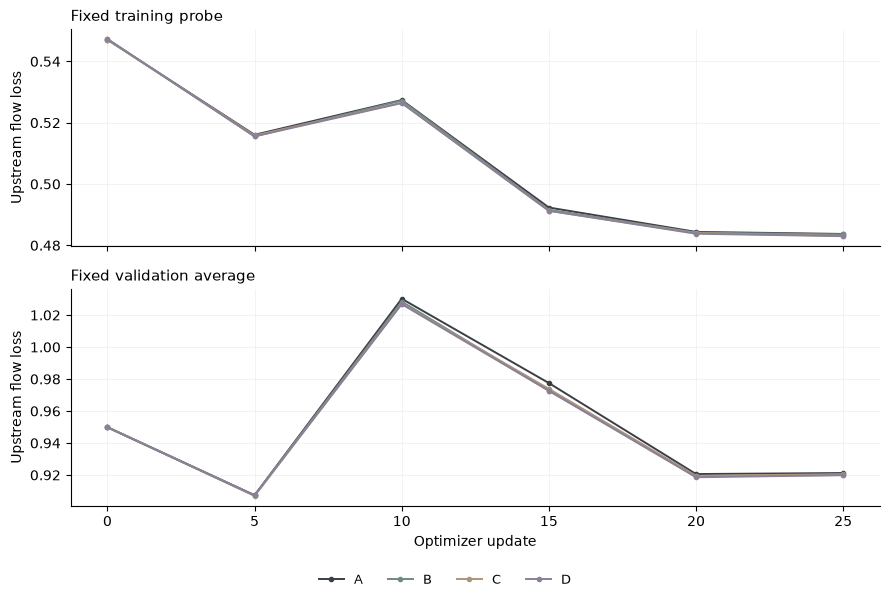

In [4]:
plt.rcParams.update({"font.size": 10, "axes.labelsize": 10, "axes.titlesize": 11,
                     "legend.fontsize": 9, "figure.facecolor": "white", "savefig.facecolor": "white"})
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
colors = ["#393f45", "#718982", "#ad9479", "#8a8098"]
for (variant, history), color in zip(bundle["loss_history"].items(), colors, strict=True):
    steps = [row["step"] for row in history]
    for ax, key in zip(axes, ["train/fixed_probe_flow_loss", "validation/flow_loss"], strict=True):
        ax.plot(steps, [row[key] for row in history], label=variant, color=color, marker="o", markersize=3, linewidth=1.4)
for ax, title in zip(axes, ["Fixed training probe", "Fixed validation average"], strict=True):
    ax.set_title(title, loc="left"); ax.set_ylabel("Upstream flow loss")
    ax.grid(alpha=0.2, linewidth=0.5); ax.spines[["top", "right"]].set_visible(False)
axes[-1].set_xlabel("Optimizer update")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=4, frameon=False)
fig.tight_layout(rect=(0, 0.05, 1, 1)); plt.show(); plt.close(fig)


## 1. Pumpkin showpiece s

Play the video, then compare the same two viewpoints for all models. Original SAM 3D uses the first frame. All other predictions below use the full video. Ground truth appears first, then native SAM 3D, earlier averaging B, and new A–D.


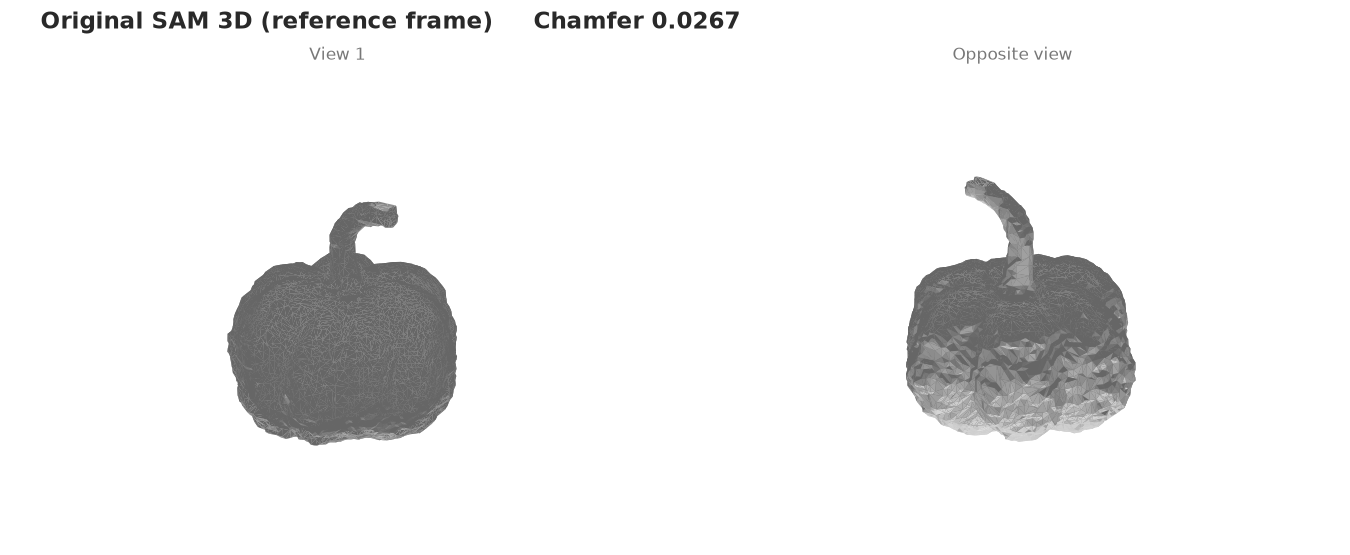
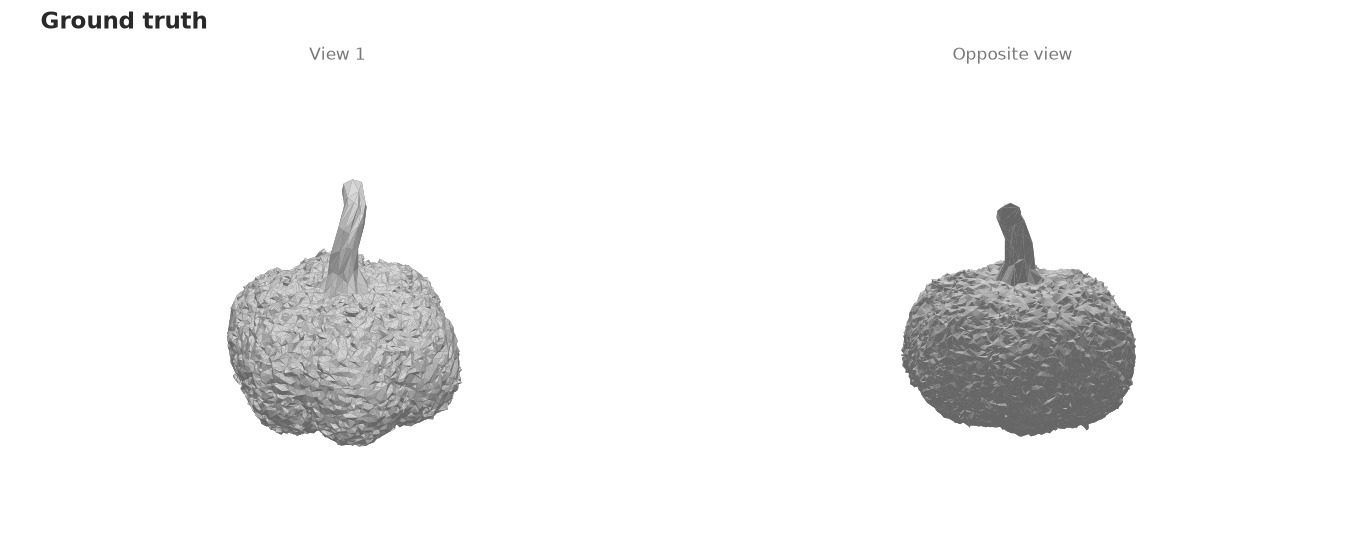


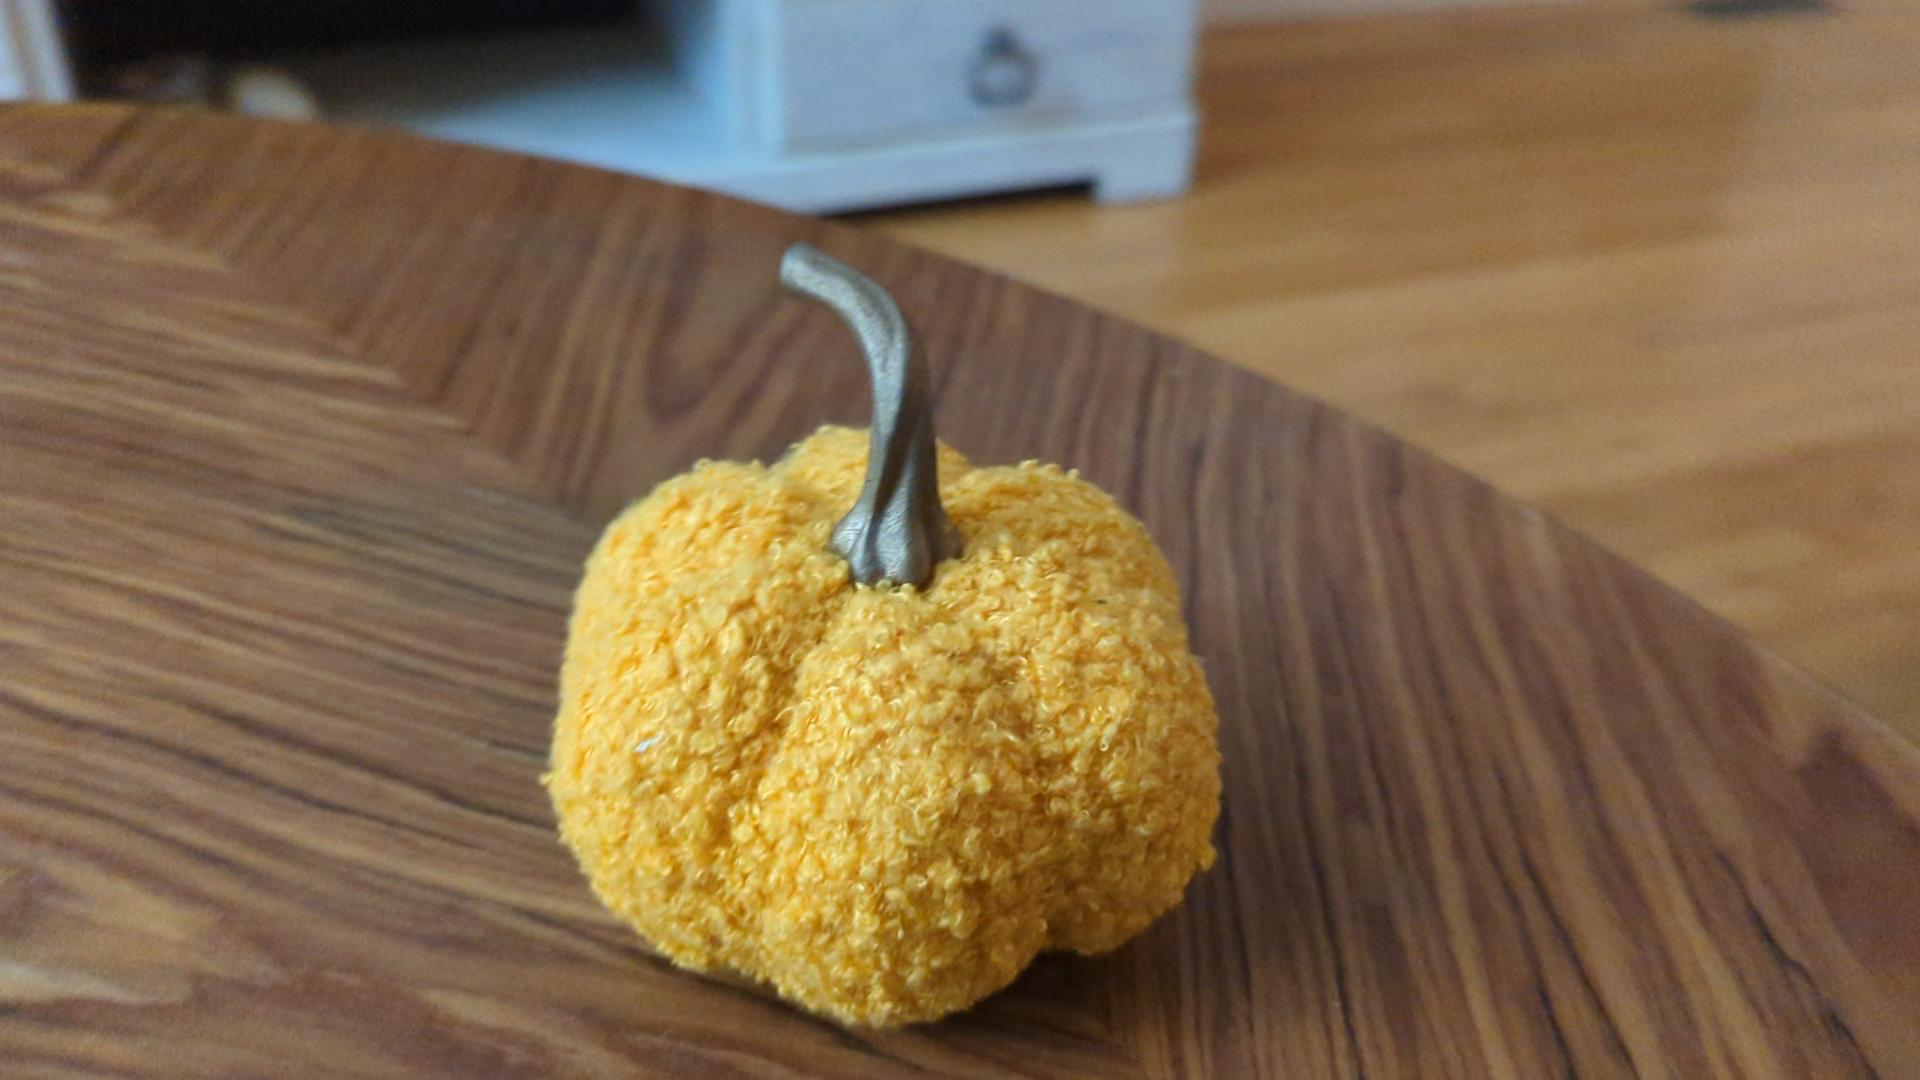
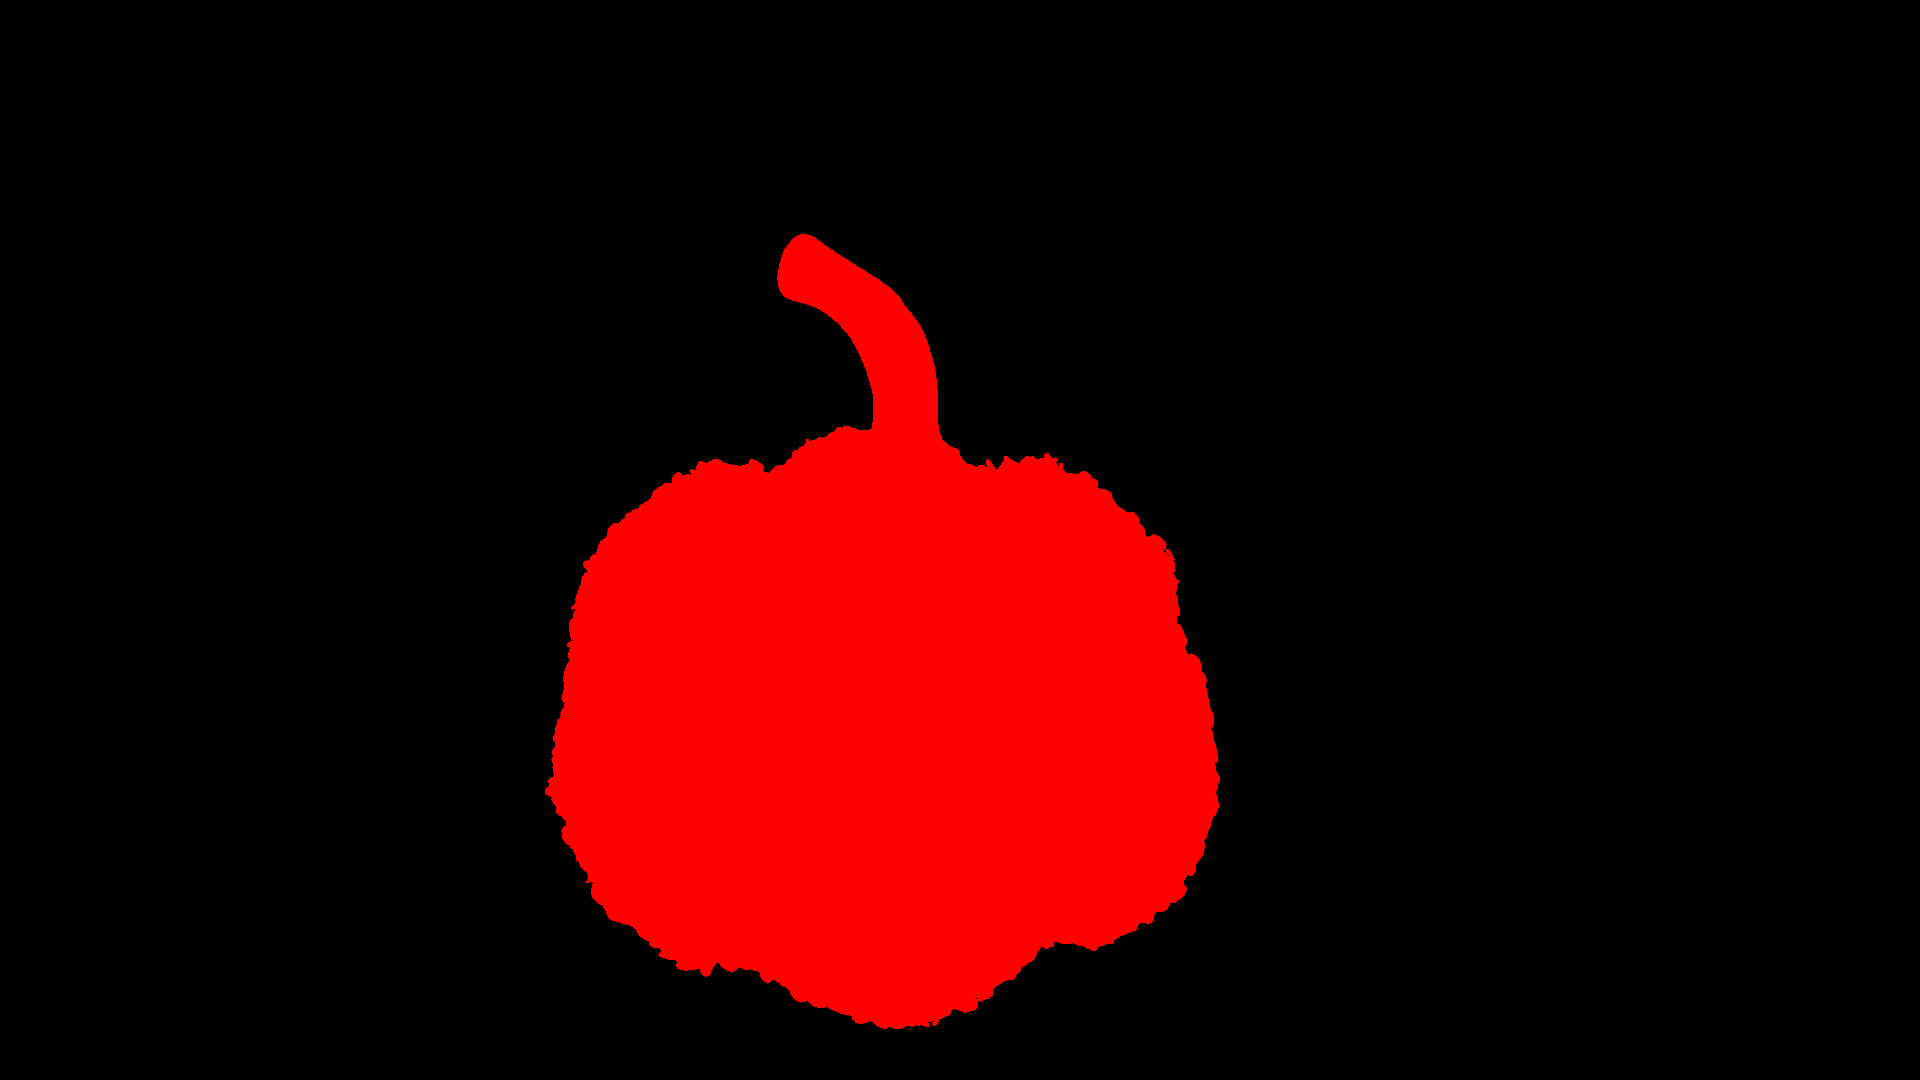

Model / W&B run,Input,Chamfer ↓,F-score ↑,Newly revealed recall ↑
Original SAM 3D (reference frame),Reference image,0.0267,0.385,0.461
Earlier averaging B,Full video,0.0825,0.142,0.093
Pooler A: connector,Full video,0.1463,0.113,0.064
Pooler B: video LoRA,Full video,0.1457,0.116,0.071
Pooler C: SAM LoRA,Full video,0.1457,0.119,0.072
Pooler D: both LoRAs,Full video,0.1457,0.117,0.070


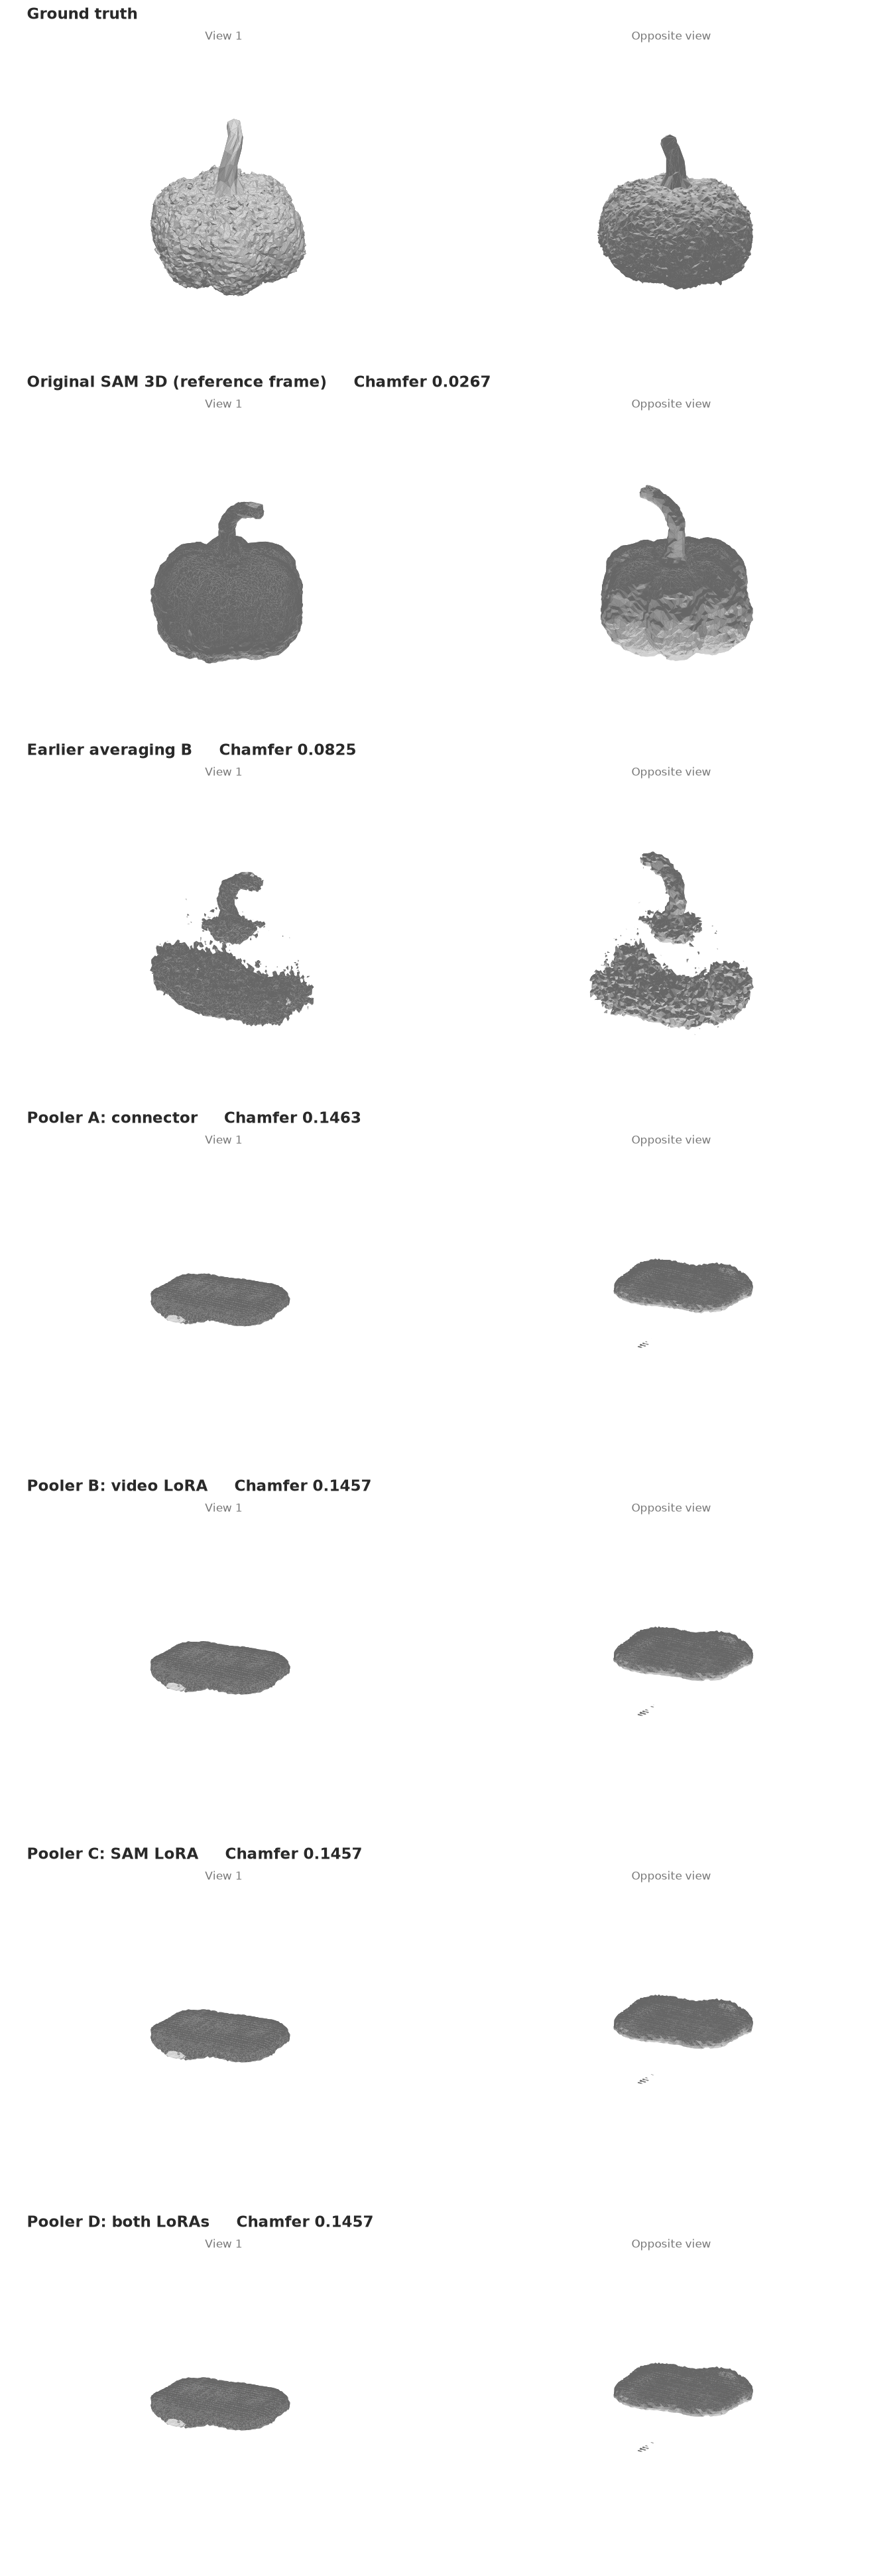

In [5]:
obj = bundle["objects"][0]
show_context(obj)
display(score_table(obj["models"]))
display(Image(filename=str(ASSETS / "preview" / obj["example_id"] / "contact.png"), width=1100))

## 2. Welcome sign mushrooms

Play the video, then compare the same two viewpoints for all models. Original SAM 3D uses the first frame. All other predictions below use the full video. Ground truth appears first, then native SAM 3D, earlier averaging B, and new A–D.


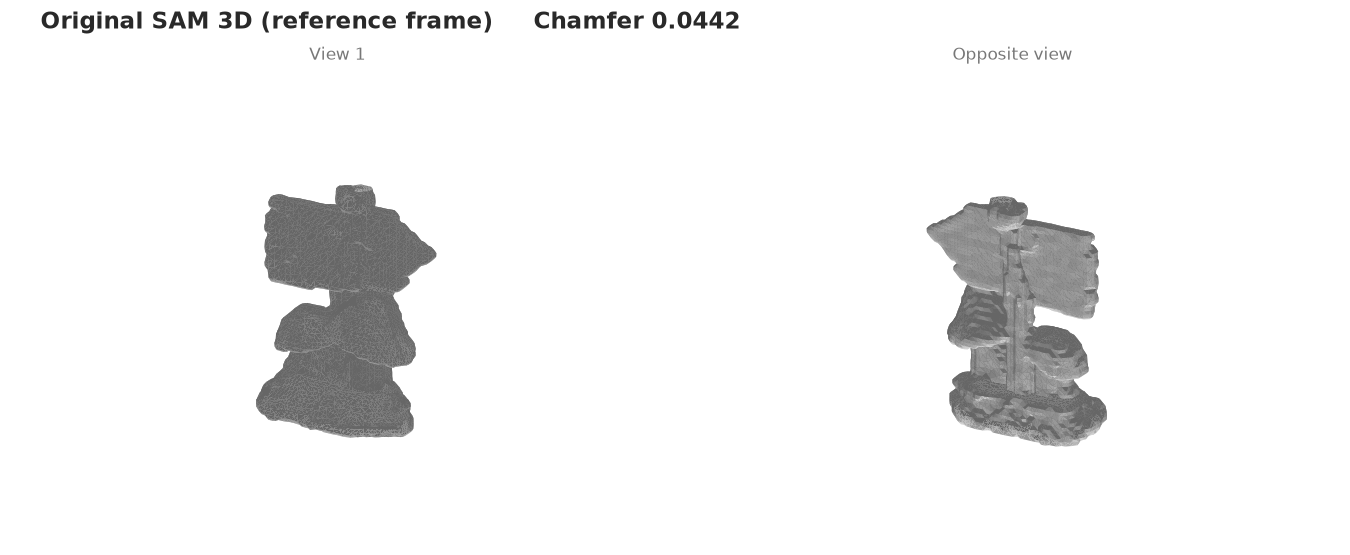
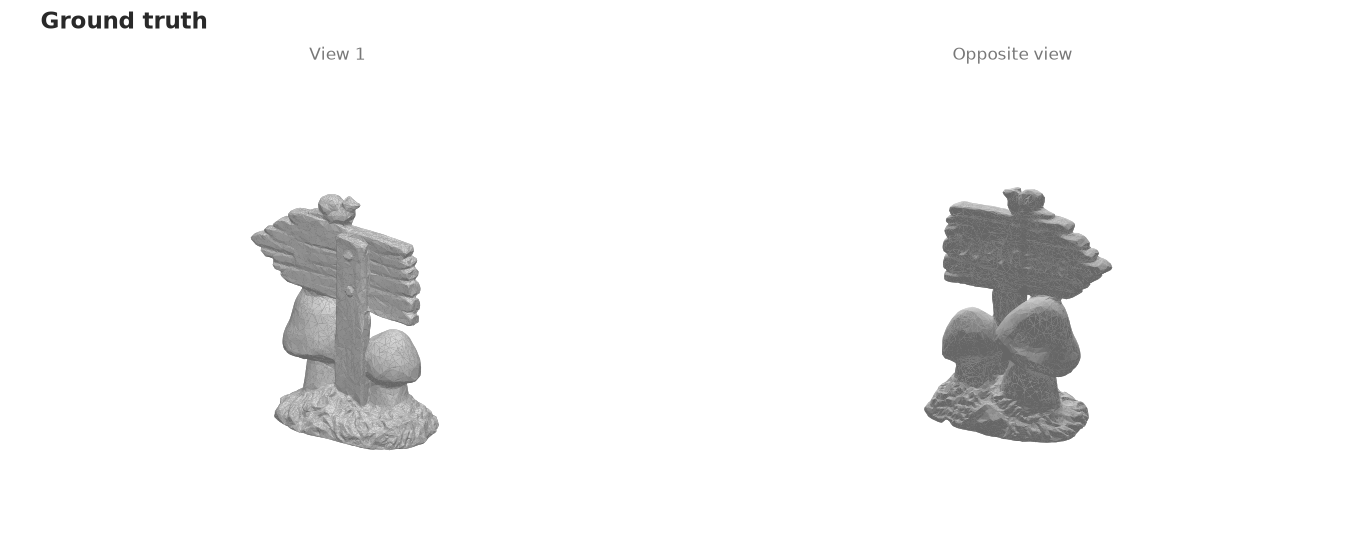


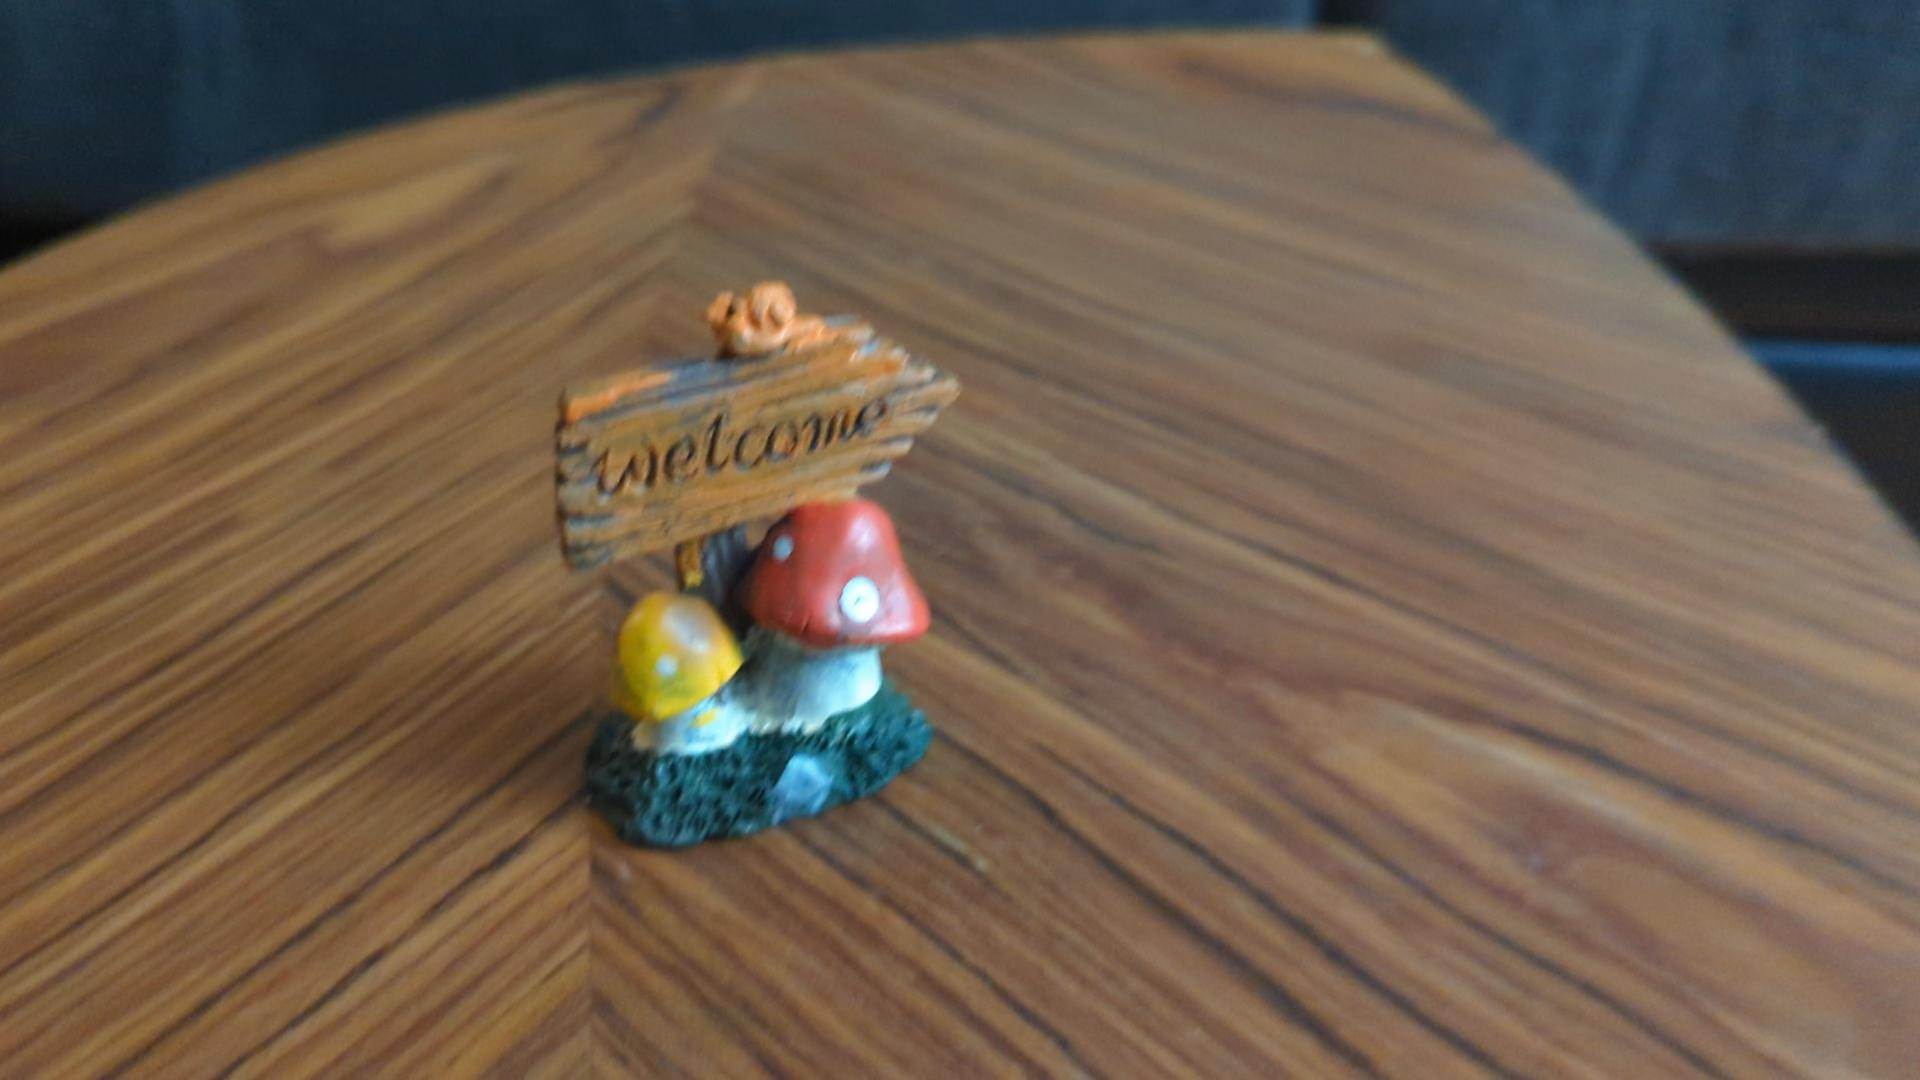
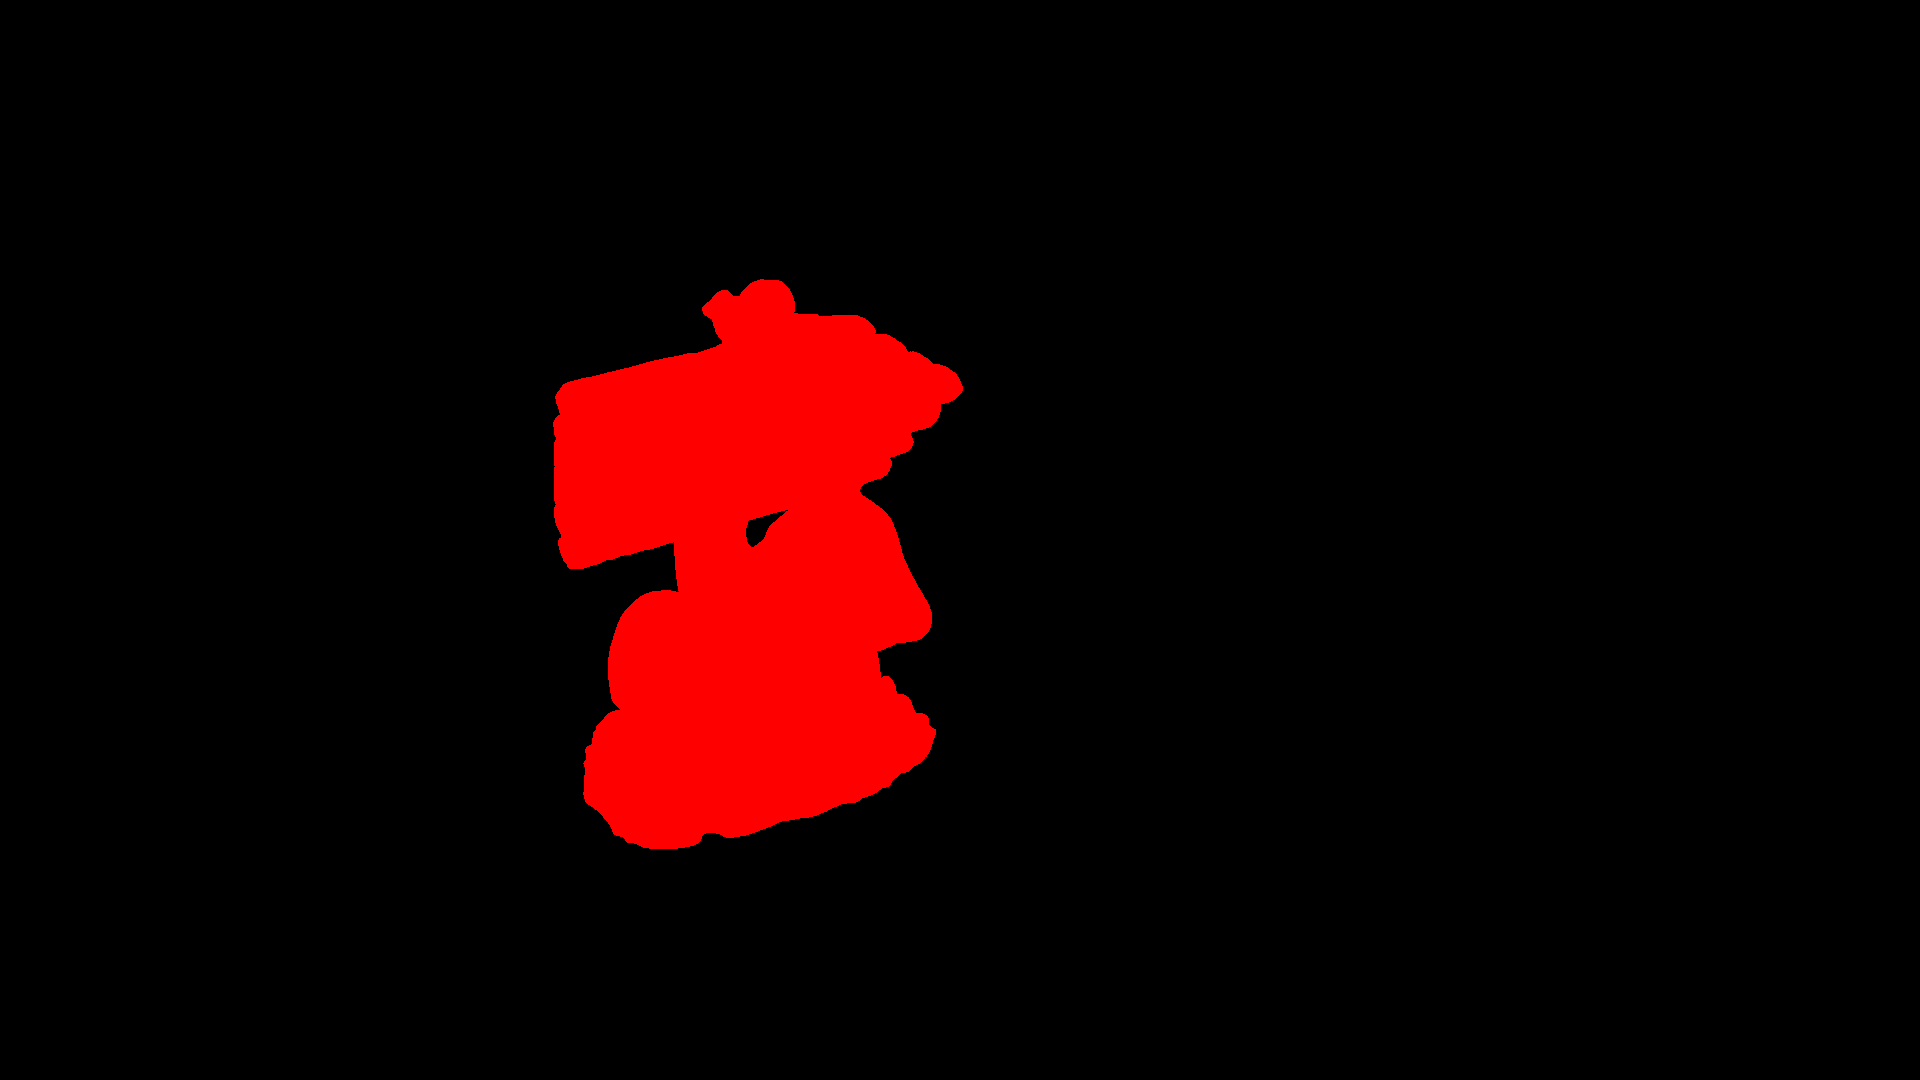

Model / W&B run,Input,Chamfer ↓,F-score ↑,Newly revealed recall ↑
Original SAM 3D (reference frame),Reference image,0.0442,0.258,0.236
Earlier averaging B,Full video,0.0398,0.305,0.260
Pooler A: connector,Full video,0.0599,0.154,0.037
Pooler B: video LoRA,Full video,0.0600,0.163,0.039
Pooler C: SAM LoRA,Full video,0.0601,0.158,0.037
Pooler D: both LoRAs,Full video,0.0599,0.161,0.042


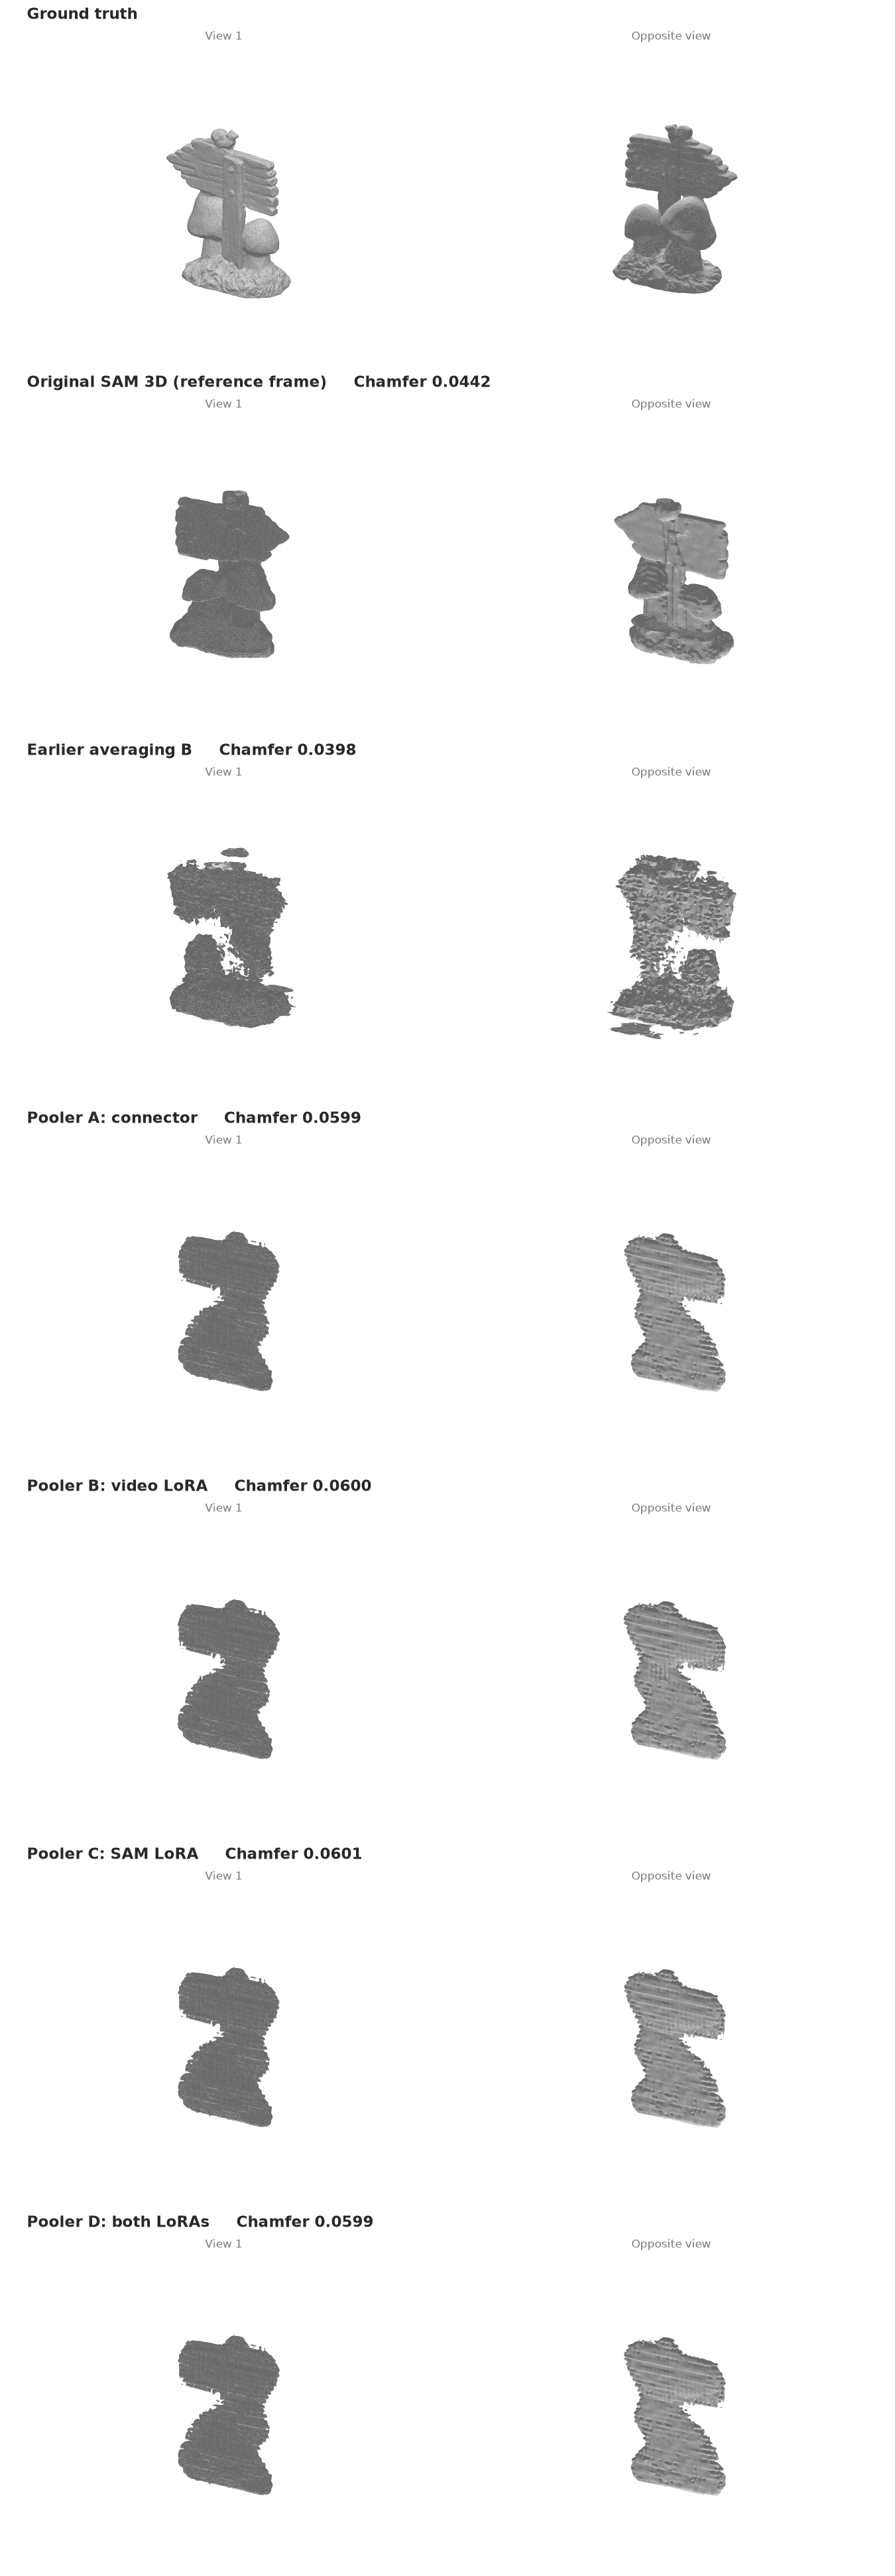

In [6]:
obj = bundle["objects"][1]
show_context(obj)
display(score_table(obj["models"]))
display(Image(filename=str(ASSETS / "preview" / obj["example_id"] / "contact.png"), width=1100))

## Interactive mesh views

This optional view uses simplified surface meshes for responsive display. All scenes have identical axis limits and initial camera settings. The original full-resolution GLBs remain in the comparison artifact; scores were computed before display simplification. Change `OBJECT_INDEX` to inspect the other object.

In [7]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import trimesh

OBJECT_INDEX = 0
obj = bundle["objects"][OBJECT_INDEX]
models = [{"key": "ground_truth", "label": "Ground truth"}] + obj["models"]
specs = [[{"type": "scene"} for _ in range(4)] for _ in range(2)]
fig = make_subplots(rows=2, cols=4, specs=specs, subplot_titles=[m["label"] for m in models] + [""])
for index, model in enumerate(models):
    mesh = trimesh.load(ASSETS / "preview" / obj["example_id"] / (model["key"] + ".glb"), force="mesh")
    vertices, faces = np.asarray(mesh.vertices).round(5), np.asarray(mesh.faces)
    fig.add_trace(go.Mesh3d(x=vertices[:,0], y=vertices[:,1], z=vertices[:,2], i=faces[:,0], j=faces[:,1], k=faces[:,2],
                           color="#999c9b", flatshading=True, name=model["label"], showscale=False,
                           lighting=dict(ambient=0.5, diffuse=0.8, specular=0.1)), row=index//4+1, col=index%4+1)
axis = dict(range=[-0.58,0.58], visible=False)
fig.update_scenes(xaxis=axis, yaxis=axis, zaxis=axis, aspectmode="cube",
                  camera=dict(eye=dict(x=1.3,y=-1.8,z=1.1), up=dict(x=0,y=0,z=1)))
fig.update_layout(height=680, width=1200, paper_bgcolor="white", showlegend=False,
                  margin=dict(l=0,r=0,t=60,b=0), title=obj["object_id"].replace("_", " "))
# Plotly scenes rotate independently; double-click a scene to reset its camera.
fig.show(renderer="plotly_mimetype")


## What this comparison shows

The new mask-aware pooler implementation trains and generates valid meshes, but its measured reconstruction quality regressed in this small pilot. Lower fixed flow loss did not imply better meshes. Only two training objects and two validation objects were active; test objects were untouched.

Pooling, full-scene preprocessing and replacement of native RGB conditioning changed together. This comparison does not isolate which change caused the regression. All model weights, losses, videos and meshes are linked to the recorded runs through the comparison artifact.